# URL Classification with XGBoost

This notebook demonstrates how to classify URLs as malicious or benign using the XGBoost classifier. The process includes data loading, feature engineering, model training with cross-validation, and making predictions on new URLs.

## 1. Importing Libraries

First, we import all the necessary libraries required for data processing, feature engineering, visualization, and model training.

In [33]:
import csv
import itertools
import numpy as np
import os
import re
import string
import hashlib
from urllib.parse import urlparse, parse_qs, urlsplit

import pandas as pd
from joblib import dump, load
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.model_selection import train_test_split, KFold
from sklearn.preprocessing import LabelEncoder

import tldextract
# from googlesearch import search  # Uncomment if needed

import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

from sklearn import metrics
from xgboost import XGBClassifier
from imblearn.over_sampling import RandomOverSampler

import ipaddress

# Set plot style for better aesthetics
sns.set(style="whitegrid")

## 2. Configuration

Set up the configuration, including the path to your dataset. Ensure you replace `'./malicious_phish.csv'` dengan path sebenarnya ke file CSV Anda yang berisi data URL.

In [34]:
# Path to your dataset CSV file
DATA_PATH = './balanced_urls.csv'

# Path to save models and encoders
MODEL_PATH = './models-balanced/final_xgb_model.pkl'
ENCODER_PATH = './models-balanced/target_encoder.pkl'
LABEL_ENCODER_PATH = './models-balanced/label_encoder.pkl'

## 3. Feature Engineering Functions

Define a series of functions to extract meaningful features from URLs. These features will help the model distinguish between malicious and benign URLs.

In [35]:
# Daftar TLD terpercaya
from constant_datas import TRUSTED_TLDS

In [36]:
from constant_datas import TRUSTED_TLDS
import re
import tldextract
from urllib.parse import urlparse, parse_qs
import ipaddress
import numpy as np

# 1. HTTPS detection with added bonus
def secure_http(url):
    """Check if the URL uses HTTPS."""
    try:
        return 1 if url.lower().startswith('https://') else 0
    except Exception as e:
        print(f"Error in secure_http: {e}")
        return 0

# 2. URL length without scheme (log transformation)
def url_length(url):
    """Calculate the length of the URL excluding the scheme."""
    try:
        stripped_url = re.sub(r'^https?://', '', url)
        return np.log(len(stripped_url) + 1)
    except Exception as e:
        print(f"Error in url_length: {e}")
        return 0

# 3. Extract subdomain with suspicious subdomain check
def find_subdomain(url):
    """Extract the subdomain and check for suspicious patterns."""
    try:
        ext = tldextract.extract(url)
        subdomain = ext.subdomain
        suspicious_subdomains = ['login', 'secure', 'admin', 'account', 'pay', 'update', 'signin', 'auth']
        return 1 if any(sub in subdomain for sub in suspicious_subdomains) else 0
    except Exception as e:
        print(f"Error in find_subdomain: {e}")
        return 0

# 4. Extract TLD (Top-Level Domain)
def get_tld_func(url):
    """Extract the top-level domain (TLD) from the URL."""
    try:
        ext = tldextract.extract(url)
        return ext.suffix if ext.suffix else 'missing'
    except Exception as e:
        print(f"Error in get_tld_func: {e}")
        return 'missing'

# 5. Count domain tokens with log transformation
def domain_token_count(url):
    """Count the number of tokens in the domain with a log transformation."""
    try:
        parsed_url = urlparse(url if urlparse(url).scheme else 'http://' + url)
        domain = parsed_url.netloc
        domain = domain.strip('[]')  # Remove IPv6 brackets if present
        return np.log(len(domain.split('.')) + 1)
    except Exception as e:
        print(f"Error in domain_token_count: {e}")
        return 0

# 6. Hostname length
def hostname_length(url):
    """Calculate the length of the hostname."""
    try:
        parsed_url = urlparse(url if urlparse(url).scheme else 'http://' + url)
        hostname = parsed_url.hostname
        return len(hostname) if hostname else 0
    except Exception as e:
        print(f"Error in hostname_length: {e}")
        return 0

# 7. Extract root domain
def extract_root_domain(url):
    """Extract the root domain from the URL."""
    try:
        extracted = tldextract.extract(url)
        return extracted.domain if extracted.domain else 'missing'
    except Exception as e:
        print(f"Error in extract_root_domain: {e}")
        return 'missing'

# 8. Count dots in the URL
def count_dot(url):
    """Count the number of dots in the URL."""
    try:
        return url.count('.')
    except Exception as e:
        print(f"Error in count_dot: {e}")
        return 0

# 9. Count directories in the URL path
def no_of_dir(url):
    """Count the number of directories in the URL path."""
    try:
        path = urlparse(url).path
        return path.count('/')
    except Exception as e:
        print(f"Error in no_of_dir: {e}")
        return 0

# 10. Count digits in the URL
def digit_count(url):
    """Count the number of digits in the URL."""
    try:
        return sum(c.isdigit() for c in url)
    except Exception as e:
        print(f"Error in digit_count: {e}")
        return 0

# 11. Count letters in the URL
def letter_count(url):
    """Count the number of letters in the URL."""
    try:
        return sum(c.isalpha() for c in url)
    except Exception as e:
        print(f"Error in letter_count: {e}")
        return 0

# 12. First directory length in the path
def fd_length(url):
    """Calculate the length of the first directory in the URL path."""
    try:
        urlpath = urlparse(url).path
        return len(urlpath.split('/')[1]) if len(urlpath.split('/')) > 1 else 0
    except Exception as e:
        print(f"Error in fd_length: {e}")
        return 0

# 13. Length of the URL path
def path_length(url):
    """Calculate the length of the URL path."""
    try:
        parsed_url = urlparse(url)
        path = parsed_url.path
        return len(path)
    except Exception as e:
        print(f"Error in path_length: {e}")
        return 0

# 14. Number of query components
def num_query_components(url):
    """Count the number of query components in the URL."""
    try:
        parsed_url = urlparse(url)
        return len(parse_qs(parsed_url.query))
    except Exception as e:
        print(f"Error in num_query_components: {e}")
        return 0

# 15. Detect URL shortening service
def shortening_service(url):
    """Detect if the URL is using a URL shortening service."""
    try:
        pattern = re.compile(r'bit\.ly|goo\.gl|tinyurl|t\.co|ow\.ly|is\.gd|buff\.ly|ift\.tt|tiny\.cc|cut\.ly', re.IGNORECASE)
        return 1 if pattern.search(url) else 0
    except Exception as e:
        print(f"Error in shortening_service: {e}")
        return 0

# 16. Abnormal URL (hostname appears more than once)
def abnormal_url(url):
    """Detect if the hostname appears more than once in the URL."""
    try:
        parsed_url = urlparse(url)
        hostname = parsed_url.hostname
        if hostname and url.count(hostname) > 1:
            return 1
        return 0
    except Exception as e:
        print(f"Error in abnormal_url: {e}")
        return 0

# 17. Detect suspicious words in URL
def suspicious_words(url):
    """Detect suspicious words in the URL."""
    try:
        suspicious_terms = [
            'paypal', 'login', 'signin', 'bank', 'account', 'update', 'free',
            'secure', 'verify', 'transaction', 'click', 'prize', 'urgent', 'scam',
            'fraud', 'offer', 'membership', 'exclusive', 'win', 'alert', 'deal',
            'confirm', 'subscription', 'invoice', 'billing', 'refund', 'withdraw', 'auth', 'payment', 'locked'
        ]
        return 1 if any(term in url.lower() for term in suspicious_terms) else 0
    except Exception as e:
        print(f"Error in suspicious_words: {e}")
        return 0

# 18. Detect if URL contains IP address
def having_ip_address(url):
    """Detect if the URL contains an IP address."""
    try:
        parsed_url = urlparse(url)
        hostname = parsed_url.hostname
        if hostname:
            ip = ipaddress.ip_address(hostname)
            return 1 if isinstance(ip, (ipaddress.IPv4Address, ipaddress.IPv6Address)) else 0
        return 0
    except ValueError:
        return 0
    except Exception as e:
        print(f"Error in having_ip_address: {e}")
        return 0

# 19. Check if the URL contains certain file extensions
def contains_file(url):
    """Check if the URL contains suspicious file extensions."""
    try:
        filetypes = ['.html', '.txt', '.pdf', '.jpg', '.png', '.exe', '.php', '.zip', '.rar', '.js']
        return 1 if any(url.lower().endswith(ext) for ext in filetypes) else 0
    except Exception as e:
        print(f"Error in contains_file: {e}")
        return 0

# 20. Check if URL path is unusually long or contains suspicious characters
def path_abnormal(url):
    """Check if the URL path contains suspicious patterns."""
    try:
        path = urlparse(url).path
        if len(path) > 100 or re.search(r'[\\?%*:#<>]', path):
            return 1
        return 0
    except Exception as e:
        print(f"Error in path_abnormal: {e}")
        return 0

# 21. Check if URL contains Cyrillic characters
def contains_cyrillic(url):
    """Check if the URL contains Cyrillic characters."""
    try:
        return 1 if re.search('[\u0400-\u04FF]', url) else 0
    except Exception as e:
        print(f"Error in contains_cyrillic: {e}")
        return 0

# 22. Check if TLD is trusted
def is_trusted_tld(url, weight=10, https_bonus=5, cyrillic_penalty=5):
    """Determine if the TLD of the URL is trusted."""
    try:
        ext = tldextract.extract(url)
        tld = ext.suffix.lower()
        is_trusted = tld in TRUSTED_TLDS
        uses_https = url.lower().startswith('https://')
        has_cyrillic = contains_cyrillic(url)

        tld_score = weight if is_trusted else 0
        https_score = https_bonus if uses_https else 0
        cyrillic_score = -cyrillic_penalty if has_cyrillic else 0

        return tld_score + https_score + cyrillic_score
    except Exception as e:
        print(f"Error in is_trusted_tld: {e}")
        return 0

# Add entropy as a feature
def calculate_entropy(url):
    """Calculate entropy of the URL. Entropy measures the randomness or unpredictability in the character distribution of a URL. Higher entropy values are often associated with obfuscation techniques used in malicious URLs."""
    try:
        url = url.lower()
        prob = [float(url.count(c)) / len(url) for c in dict.fromkeys(list(url))]
        entropy = - sum([p * np.log2(p) for p in prob])
        return entropy
    except Exception as e:
        print(f"Error in calculate_entropy: {e}")
        return 0

# Add ratio of special characters to URL length
def special_char_ratio(url):
    """Calculate ratio of special characters to URL length."""
    try:
        special_chars = sum(1 for c in url if not c.isalnum())
        return special_chars / len(url) if len(url) > 0 else 0
    except Exception as e:
        print(f"Error in special_char_ratio: {e}")
        return 0


# ======================================
# 4. Loading the Dataset
# ======================================

In [37]:
# Load Data
try:
    data = pd.read_csv(DATA_PATH)
    print(f"Dataset loaded successfully with shape: {data.shape}")
    
    # Remove duplicates
    data = data.drop_duplicates()
    print(f"Dataset shape after removing duplicates: {data.shape}")
except FileNotFoundError:
    print(f"Error: File not found at {DATA_PATH}. Please check the path.")
    exit(1)
except Exception as e:
    print(f"An error occurred while loading the data: {e}")
    exit(1)

Dataset loaded successfully with shape: (633020, 3)
Dataset shape after removing duplicates: (633010, 3)


# ======================================
# 5. Exploring the Dataset
# ======================================

In [38]:
print("\nFirst 5 rows of the dataset:")
print(data.head())

print("\nClass Distribution:")
print(data['label'].value_counts())


First 5 rows of the dataset:
                                                 url   label  result
0                             https://www.google.com  benign       0
1          https://spada.upnyk.ac.id/login/index.php  benign       0
2                         https://spada.upnyk.ac.id/  benign       0
3  https://spada.upnyk.ac.id/login/forgot_passwor...  benign       0
4                          https://bima.upnyk.ac.id/  benign       0

Class Distribution:
label
malicious    316561
benign       316449
Name: count, dtype: int64


# ======================================
# 6. Visualizing Word Clouds
# ======================================

Generate word clouds for each class to visualize common patterns in URLs.

In [39]:
def plot_wordcloud(data_subset, title):
    """Plot a word cloud for a given subset of data."""
    combined_urls = " ".join(i for i in data_subset.url if isinstance(i, str))
    wordcloud = WordCloud(width=1600, height=800, colormap='Paired', background_color='black').generate(combined_urls)
    # plt.figure(figsize=(12, 14), facecolor='k')
    # plt.imshow(wordcloud, interpolation='bilinear')
    # plt.axis("off")
    # plt.title(title, color='white')
    # plt.tight_layout(pad=0)
    # plt.show()

# Plot wordclouds for each class
classes = data['label'].unique()
for cls in classes:
    subset = data[data.label == cls]
    # plot_wordcloud(subset, f"{cls.capitalize()} URLs Wordcloud")

# *This will display word clouds for each class (`benign`, `malicious`, etc.), highlighting the most frequent words in the URLs.*

# ======================================
# 7. Feature Engineering
# ======================================

Apply the previously defined feature engineering functions to extract features from the URLs.

In [40]:
from constant_datas import TRUSTED_TLDS
import pandas as pd
import re
import tldextract
from urllib.parse import urlparse, parse_qs
import ipaddress
import numpy as np

# Example of the updated feature engineering pipeline
print("\nStarting feature engineering...")

# Apply feature engineering functions
data['secure_http'] = data['url'].apply(secure_http)
data['url_length'] = data['url'].apply(url_length)
data['find_subdomain'] = data['url'].apply(find_subdomain)
data['tld'] = data['url'].apply(get_tld_func)
data['domain_token_count'] = data['url'].apply(domain_token_count)
data['hostname_length'] = data['url'].apply(hostname_length)
data['root_domain'] = data['url'].apply(extract_root_domain)
data['count_dot'] = data['url'].apply(count_dot)
data['count_dir'] = data['url'].apply(no_of_dir)
data['count_percent'] = data['url'].apply(lambda x: x.count('%') if isinstance(x, str) else 0)
data['count_question'] = data['url'].apply(lambda x: x.count('?') if isinstance(x, str) else 0)
data['count_hyphen'] = data['url'].apply(lambda x: x.count('-') if isinstance(x, str) else 0)
data['count_equals'] = data['url'].apply(lambda x: x.count('=') if isinstance(x, str) else 0)
data['count_digits'] = data['url'].apply(digit_count)
data['count_letters'] = data['url'].apply(letter_count)
data['fd_length'] = data['url'].apply(fd_length)
data['path_length'] = data['url'].apply(path_length)
data['num_query_components'] = data['url'].apply(num_query_components)
data['short_url'] = data['url'].apply(shortening_service)
data['abnormal_url'] = data['url'].apply(abnormal_url)
data['sus_url'] = data['url'].apply(suspicious_words)
data['use_of_ip'] = data['url'].apply(having_ip_address)
data['contains_file'] = data['url'].apply(contains_file)
data['path_abnormal'] = data['url'].apply(path_abnormal)
data['entropy'] = data['url'].apply(calculate_entropy)
data['special_char_ratio'] = data['url'].apply(special_char_ratio)

# Apply is_trusted_tld with parameter weight and https_bonus
data['is_trusted_tld'] = data['url'].apply(lambda url: is_trusted_tld(url, weight=10, https_bonus=5))

# Add the new feature for Cyrillic checking
data['contains_cyrillic'] = data['url'].apply(contains_cyrillic)

# Add combination features
data['trusted_and_https'] = data['is_trusted_tld'] * data['secure_http']
data['entropy_special_char'] = data['entropy'] * data['special_char_ratio']

# Select Feature Columns, add 'trusted_and_https', 'contains_cyrillic', 'entropy', 'special_char_ratio', and combinations
feature_columns = [
    'secure_http', 'url_length', 'find_subdomain', 'tld', 'domain_token_count',
    'hostname_length', 'root_domain', 'count_dot', 'count_dir', 'count_percent', 'count_question',
    'count_hyphen', 'count_equals', 'count_digits', 'count_letters', 'fd_length',
    'path_length', 'num_query_components', 'short_url', 'abnormal_url',
    'sus_url', 'use_of_ip', 'contains_file', 'path_abnormal', 'is_trusted_tld',
    'trusted_and_https', 'contains_cyrillic', 'entropy', 'special_char_ratio', 'entropy_special_char'
]

# ======================================
# 8. Feature Selection
# ======================================

# Select the relevant features for model training
X = data[feature_columns]
y = data['label']

print("\nFeature matrix X shape:", X.shape)
print("Target vector y distribution:")
print(y.value_counts())



Starting feature engineering...

Feature matrix X shape: (633010, 30)
Target vector y distribution:
label
malicious    316561
benign       316449
Name: count, dtype: int64


# ======================================
# 9. Label Encoding
# ======================================

Encode the target labels into numerical values suitable for model training.

In [41]:
print("\nEncoding target labels...")

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)
print("Classes found and their corresponding encoded labels:")
for idx, class_label in enumerate(label_encoder.classes_):
    print(f"{class_label}: {idx}")

# Save the label encoder for future use
dump(label_encoder, LABEL_ENCODER_PATH)
print(f"Label encoder saved to {LABEL_ENCODER_PATH}")


Encoding target labels...
Classes found and their corresponding encoded labels:
benign: 0
malicious: 1
Label encoder saved to ./models-balanced/label_encoder.pkl


# ======================================
# 10. Handling Missing Values for Categorical Features
# ======================================

Mengisi nilai null di fitur kategorikal sebelum melakukan encoding.

In [42]:
# Mengisi nilai null di fitur kategorikal yang akan di-encode
X[['find_subdomain', 'tld', 'root_domain']] = X[['find_subdomain', 'tld', 'root_domain']].fillna('missing')

# Verifikasi tidak ada nilai null di kolom kategorikal
print("\nNull values after filling:")
print(X[['find_subdomain', 'tld', 'root_domain']].isnull().sum())


Null values after filling:
find_subdomain    0
tld               0
root_domain       0
dtype: int64


/var/folders/2t/4pk9n9cn4vq4vq2kybwvrbqc0000gn/T/ipykernel_46737/1592181067.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X[['find_subdomain', 'tld', 'root_domain']] = X[['find_subdomain', 'tld', 'root_domain']].fillna('missing')


# ======================================
# 11. Encoding Categorical Features with TargetEncoder
# ======================================

Gunakan `TargetEncoder` untuk meng-encode fitur kategorikal.

In [43]:
from category_encoders import TargetEncoder

# Initialize the TargetEncoder dengan kolom yang akan di-encode
encoder = TargetEncoder(cols=['find_subdomain', 'tld', 'root_domain'])

# Fit encoder pada data training
encoder.fit(X, y_encoded)

# Transform data training
X_encoded = encoder.transform(X)

print("\nFeature engineering completed. Here's a preview:")
print(X_encoded.head())

# Save the encoder for future use
dump(encoder, ENCODER_PATH)
print(f"Target encoder saved to {ENCODER_PATH}")


Feature engineering completed. Here's a preview:
   secure_http  url_length  find_subdomain       tld  domain_token_count  \
0            1    2.708050        0.497202  0.356650            1.386294   
1            1    3.526361        0.497202  0.922728            1.609438   
2            1    2.944439        0.497202  0.922728            1.609438   
3            1    3.784190        0.497202  0.922728            1.609438   
4            1    2.890372        0.497202  0.922728            1.609438   

   hostname_length  root_domain  count_dot  count_dir  count_percent  ...  \
0               14     0.772267          2          0              0  ...   
1               17     0.401163          4          2              0  ...   
2               17     0.401163          3          1              0  ...   
3               17     0.401163          4          2              0  ...   
4               16     0.401163          3          1              0  ...   

   sus_url  use_of_ip  contain

# ======================================
# 12. Cross-Validation with XGBoost
# ======================================

Perform k-fold cross-validation to evaluate the model's performance across different subsets of the data.


--- Fold 1 ---

Classification Report:
              precision    recall  f1-score   support

      benign       1.00      1.00      1.00     39508
   malicious       1.00      1.00      1.00     39619

    accuracy                           1.00     79127
   macro avg       1.00      1.00      1.00     79127
weighted avg       1.00      1.00      1.00     79127

Accuracy: 0.999
F1 Score: 0.999
ROC AUC Score: 1.000


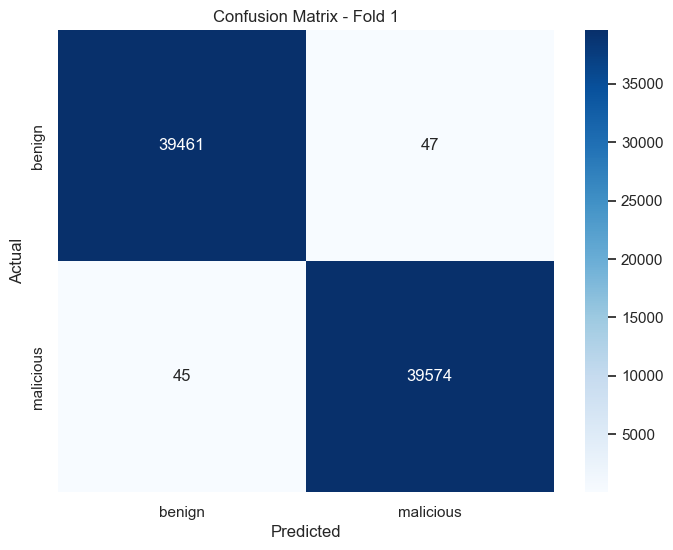

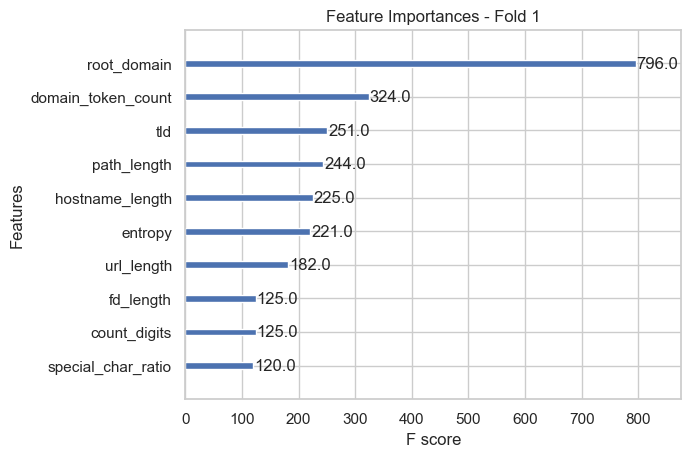


--- Fold 2 ---

Classification Report:
              precision    recall  f1-score   support

      benign       1.00      1.00      1.00     39394
   malicious       1.00      1.00      1.00     39733

    accuracy                           1.00     79127
   macro avg       1.00      1.00      1.00     79127
weighted avg       1.00      1.00      1.00     79127

Accuracy: 0.999
F1 Score: 0.999
ROC AUC Score: 1.000


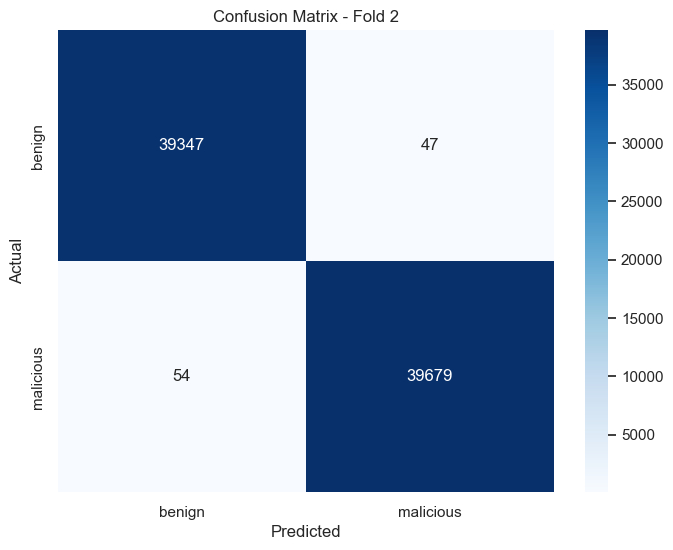

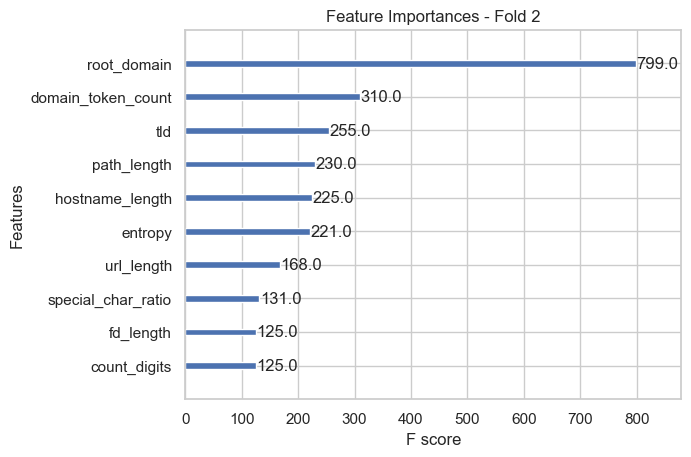


--- Fold 3 ---

Classification Report:
              precision    recall  f1-score   support

      benign       1.00      1.00      1.00     39440
   malicious       1.00      1.00      1.00     39686

    accuracy                           1.00     79126
   macro avg       1.00      1.00      1.00     79126
weighted avg       1.00      1.00      1.00     79126

Accuracy: 0.999
F1 Score: 0.999
ROC AUC Score: 1.000


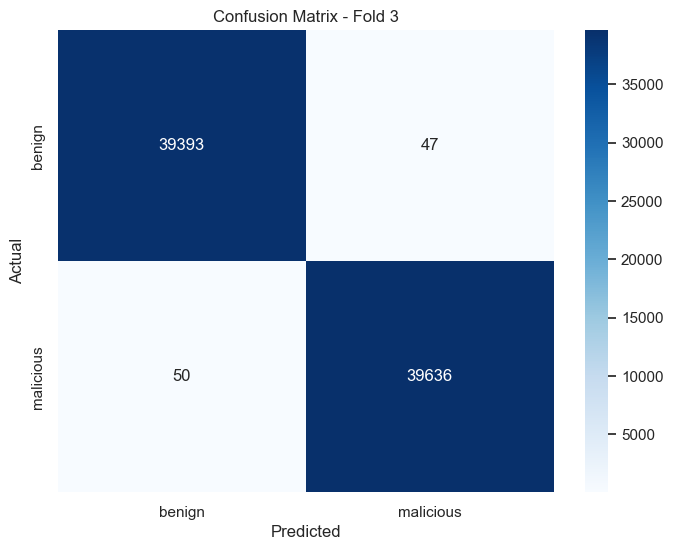

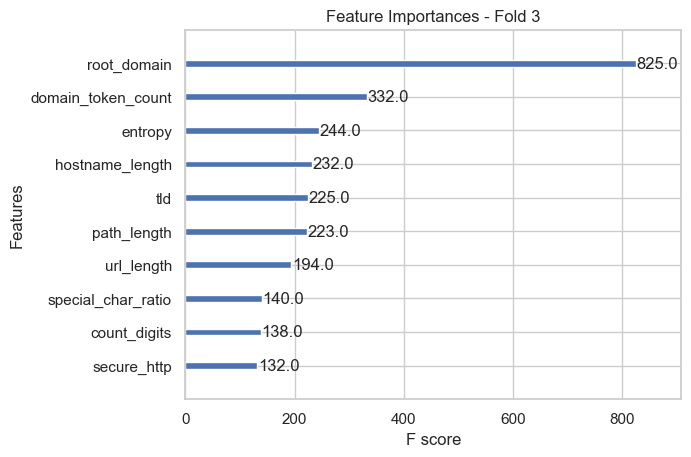


--- Fold 4 ---

Classification Report:
              precision    recall  f1-score   support

      benign       1.00      1.00      1.00     39474
   malicious       1.00      1.00      1.00     39652

    accuracy                           1.00     79126
   macro avg       1.00      1.00      1.00     79126
weighted avg       1.00      1.00      1.00     79126

Accuracy: 0.999
F1 Score: 0.999
ROC AUC Score: 1.000


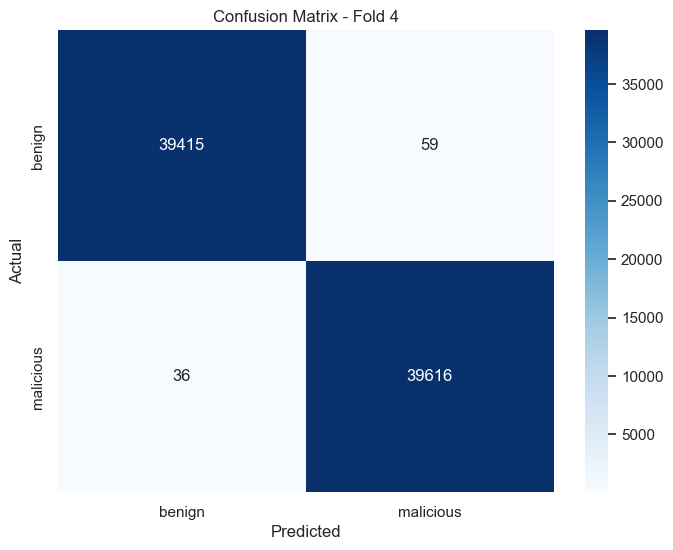

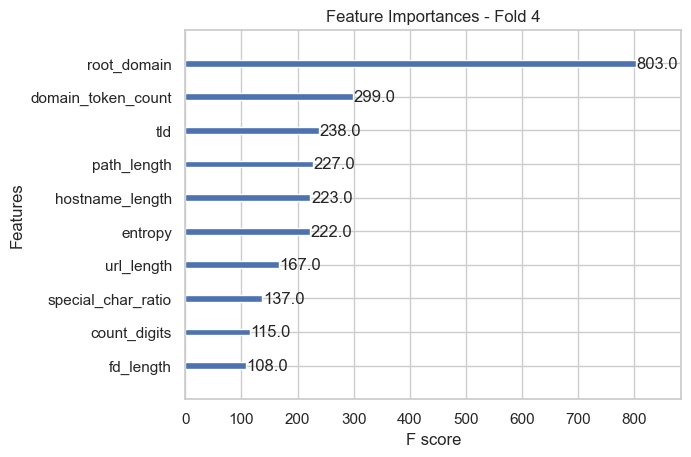


--- Fold 5 ---

Classification Report:
              precision    recall  f1-score   support

      benign       1.00      1.00      1.00     39824
   malicious       1.00      1.00      1.00     39302

    accuracy                           1.00     79126
   macro avg       1.00      1.00      1.00     79126
weighted avg       1.00      1.00      1.00     79126

Accuracy: 0.999
F1 Score: 0.999
ROC AUC Score: 1.000


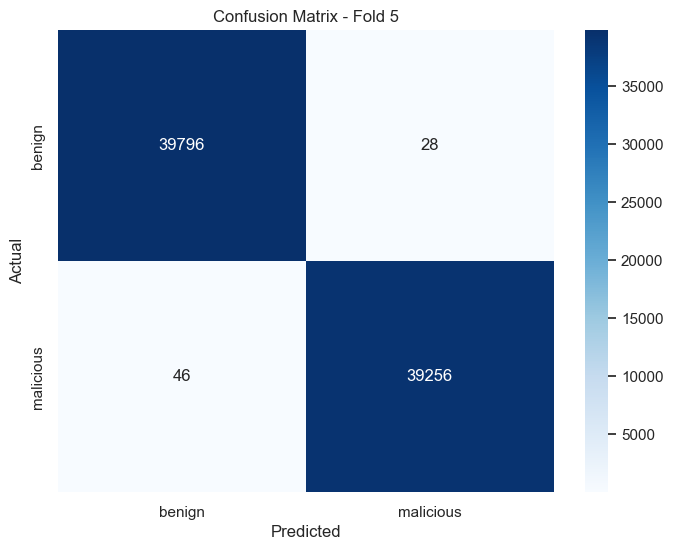

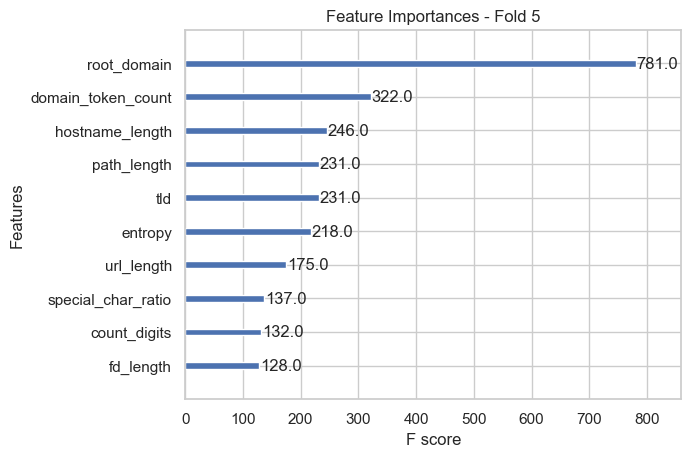


--- Fold 6 ---

Classification Report:
              precision    recall  f1-score   support

      benign       1.00      1.00      1.00     39418
   malicious       1.00      1.00      1.00     39708

    accuracy                           1.00     79126
   macro avg       1.00      1.00      1.00     79126
weighted avg       1.00      1.00      1.00     79126

Accuracy: 0.999
F1 Score: 0.999
ROC AUC Score: 1.000


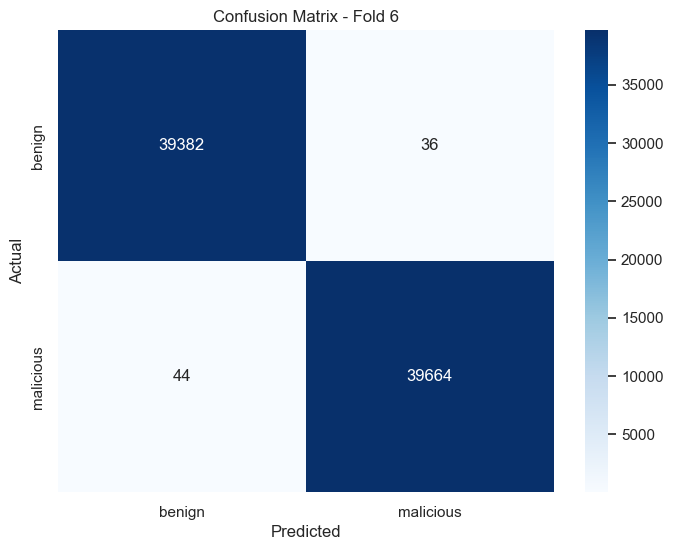

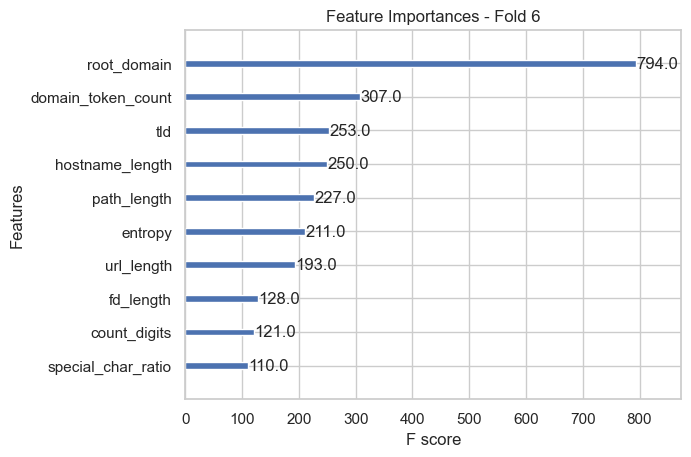


--- Fold 7 ---

Classification Report:
              precision    recall  f1-score   support

      benign       1.00      1.00      1.00     39735
   malicious       1.00      1.00      1.00     39391

    accuracy                           1.00     79126
   macro avg       1.00      1.00      1.00     79126
weighted avg       1.00      1.00      1.00     79126

Accuracy: 0.999
F1 Score: 0.999
ROC AUC Score: 1.000


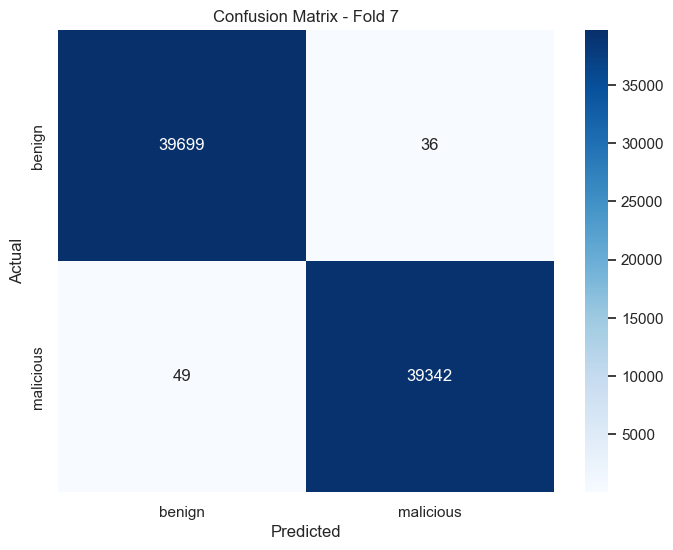

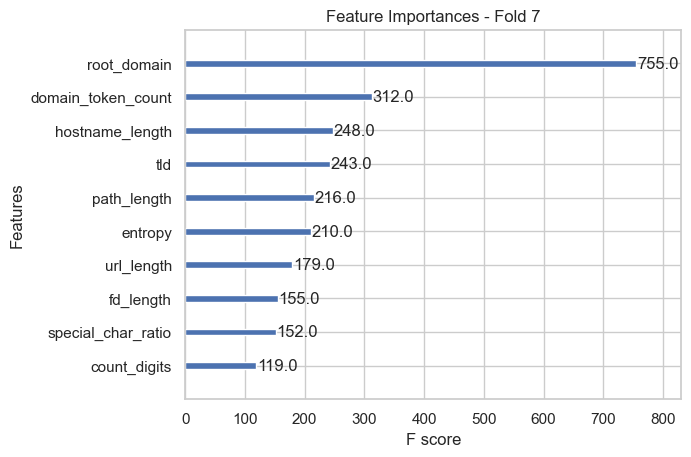


--- Fold 8 ---

Classification Report:
              precision    recall  f1-score   support

      benign       1.00      1.00      1.00     39656
   malicious       1.00      1.00      1.00     39470

    accuracy                           1.00     79126
   macro avg       1.00      1.00      1.00     79126
weighted avg       1.00      1.00      1.00     79126

Accuracy: 0.998
F1 Score: 0.998
ROC AUC Score: 1.000


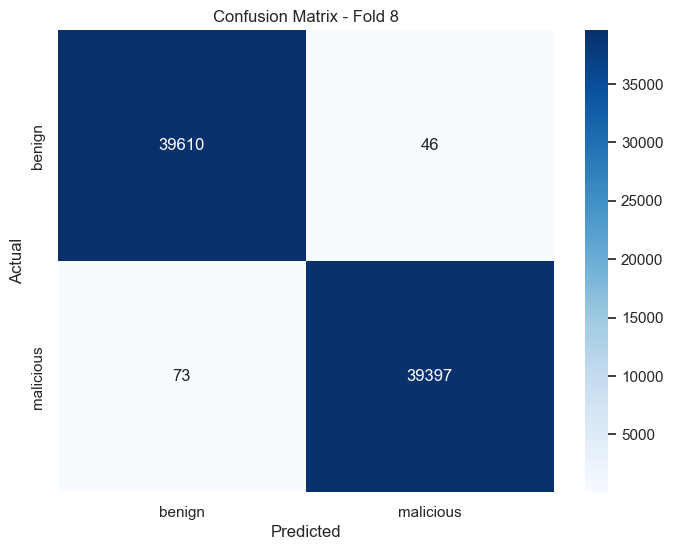

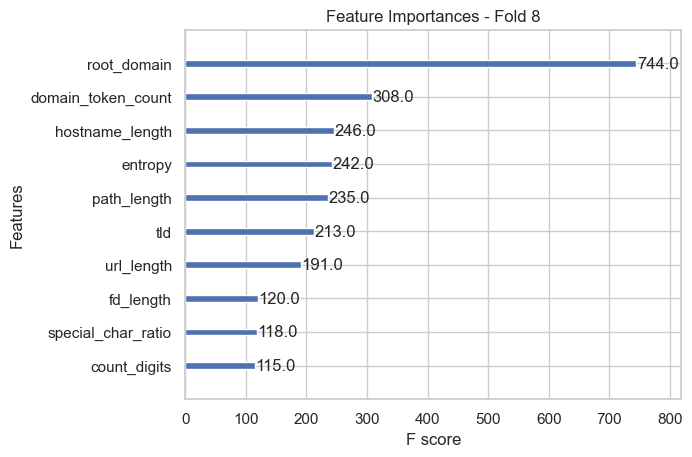


--- Final Results ---
Average Accuracy: 0.999
Average F1 Score: 0.999
Average ROC AUC Score: 1.000


In [44]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import KFold
from xgboost import XGBClassifier, plot_importance
from sklearn import metrics
from category_encoders import TargetEncoder
from sklearn.preprocessing import LabelEncoder

# Initialize TargetEncoder
encoder = TargetEncoder(cols=['find_subdomain', 'tld', 'root_domain'])

# Fit encoder on training data
encoder.fit(X, y_encoded)

# Transform training data
X_encoded = encoder.transform(X)

# Initialize label encoder for target (assuming y_encoded is already encoded)
label_encoder = LabelEncoder()
# Ensure it's encoded before training
y_encoded = label_encoder.fit_transform(y)

# Ensure y_encoded is a 1D array
y_encoded = y_encoded.ravel()

# Initialize k-fold cross-validator
num_folds = 8
kf = KFold(n_splits=num_folds, shuffle=True, random_state=42)

# Lists to store metrics
accuracy_scores = []
confusion_matrices = []
f1_scores = []
roc_auc_scores = []
feature_importances_list = []

fold_number = 1

for train_index, test_index in kf.split(X_encoded, y_encoded):
    print(f"\n--- Fold {fold_number} ---")

    X_train_fold, X_test_fold = X_encoded.iloc[train_index], X_encoded.iloc[test_index]
    y_train_fold, y_test_fold = y_encoded[train_index], y_encoded[test_index]

    # Ensure y_train_fold and y_test_fold are 1D arrays
    y_train_fold = np.ravel(y_train_fold)
    y_test_fold = np.ravel(y_test_fold)

    # Initialize XGBoost Classifier without use_label_encoder
    xgb_model = XGBClassifier(
        n_estimators=100,  # Tuning n_estimators
        learning_rate=0.1,  # Tuning learning_rate
        max_depth=6,  # Tuning max_depth
        random_state=42,
        eval_metric='mlogloss',
        n_jobs=-1
    )

    # Train the model
    xgb_model.fit(X_train_fold, y_train_fold)

    # Predict on test fold
    y_pred_xgb = xgb_model.predict(X_test_fold)

    # Confusion Matrix
    cm_fold = metrics.confusion_matrix(
        y_test_fold, y_pred_xgb, labels=np.arange(len(label_encoder.classes_)))
    confusion_matrices.append(cm_fold)

    # Classification Report
    print("\nClassification Report:")
    print(metrics.classification_report(y_test_fold,
          y_pred_xgb, target_names=label_encoder.classes_))

    # Accuracy Score
    score = metrics.accuracy_score(y_test_fold, y_pred_xgb)
    print(f"Accuracy: {score:.3f}")
    accuracy_scores.append(score)

    # F1 Score
    f1_score_fold = metrics.f1_score(
        y_test_fold, y_pred_xgb, average='weighted')
    print(f"F1 Score: {f1_score_fold:.3f}")
    f1_scores.append(f1_score_fold)

    # ROC AUC Score (for multi-class classification)
    probs = xgb_model.predict_proba(X_test_fold)

    # Compute ROC AUC Score for multi-class classification
    if len(label_encoder.classes_) > 2:  # Multi-class scenario
        roc_auc_score_fold = metrics.roc_auc_score(
            y_test_fold, probs, multi_class='ovr')
    else:  # Binary classification
        roc_auc_score_fold = metrics.roc_auc_score(y_test_fold, probs[:, 1])

    print(f"ROC AUC Score: {roc_auc_score_fold:.3f}")
    roc_auc_scores.append(roc_auc_score_fold)

    # Confusion Matrix Heatmap
    cm_df_fold = pd.DataFrame(cm_fold, index=label_encoder.classes_,
                              columns=label_encoder.classes_)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm_df_fold, annot=True, fmt="d", cmap='Blues')
    plt.title(f'Confusion Matrix - Fold {fold_number}')
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.show()

    # Feature Importances using XGBoost's plot_importance
    plot_importance(xgb_model, importance_type='weight', max_num_features=10)
    plt.title(f'Feature Importances - Fold {fold_number}')
    plt.show()

    # Store feature importances
    feat_importances = pd.Series(
        xgb_model.feature_importances_, index=X_train_fold.columns)
    feature_importances_list.append(feat_importances)

    fold_number += 1

# Print average scores across all folds
print("\n--- Final Results ---")
print(f"Average Accuracy: {np.mean(accuracy_scores):.3f}")
print(f"Average F1 Score: {np.mean(f1_scores):.3f}")
print(f"Average ROC AUC Score: {np.mean(roc_auc_scores):.3f}")

# ======================================
# 13. Summary of Cross-Validation Metrics
# ======================================

Calculate and visualize the average accuracy and feature importances across all folds.


Average Accuracy Across 8 Folds: 0.999


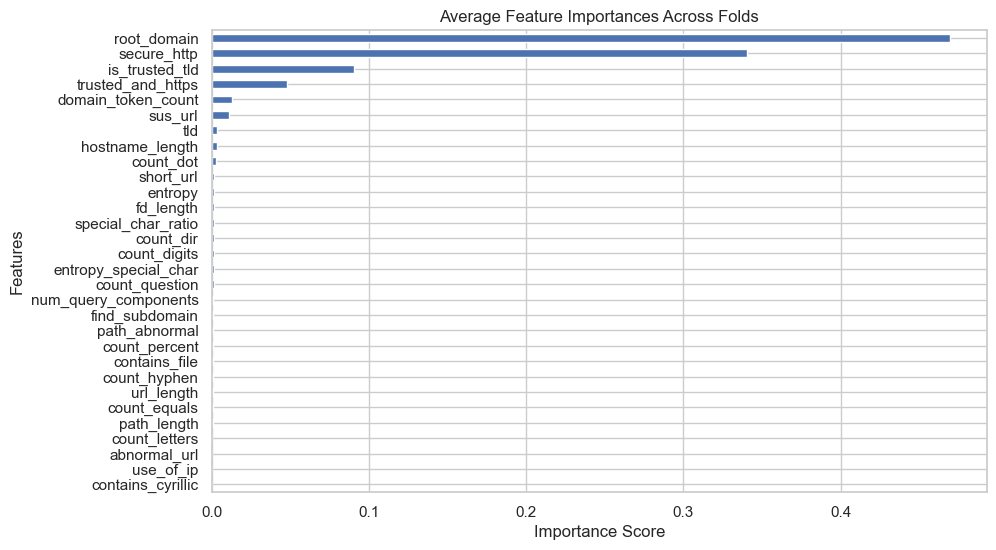

In [45]:
# Average Accuracy
average_accuracy = np.mean(accuracy_scores)
print(f"\nAverage Accuracy Across {num_folds} Folds: {average_accuracy:.3f}")

# Aggregate Feature Importances
average_feature_importances = pd.concat(feature_importances_list, axis=1).mean(axis=1).sort_values()
average_feature_importances.plot(kind="barh", figsize=(10, 6))
plt.title('Average Feature Importances Across Folds')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.show()

# ======================================
# 14. Training the Final Model
# ======================================

Train the final XGBoost model on the entire dataset after balancing it with oversampling.


Performing GridSearchCV...
Fitting 5 folds for each of 32 candidates, totalling 160 fits
[CV] END colsample_bytree=0.8, gamma=0.1, learning_rate=0.01, max_depth=4, min_child_weight=1, n_estimators=100, subsample=0.8; total time=   4.4s
[CV] END colsample_bytree=0.8, gamma=0.1, learning_rate=0.01, max_depth=4, min_child_weight=1, n_estimators=100, subsample=0.8; total time=   4.4s
[CV] END colsample_bytree=0.8, gamma=0.1, learning_rate=0.01, max_depth=4, min_child_weight=1, n_estimators=100, subsample=0.8; total time=   4.5s
[CV] END colsample_bytree=0.8, gamma=0.1, learning_rate=0.01, max_depth=4, min_child_weight=1, n_estimators=100, subsample=0.8; total time=   4.4s
[CV] END colsample_bytree=0.8, gamma=0.1, learning_rate=0.01, max_depth=4, min_child_weight=1, n_estimators=100, subsample=0.8; total time=   4.5s
[CV] END colsample_bytree=0.8, gamma=0.1, learning_rate=0.01, max_depth=4, min_child_weight=1, n_estimators=150, subsample=0.8; total time=   6.0s
[CV] END colsample_bytree=0.

/Users/kidman/.pyenv/versions/3.10.15/lib/python3.10/site-packages/joblib/externals/loky/process_executor.py:752: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


[CV] END colsample_bytree=0.8, gamma=0.2, learning_rate=0.1, max_depth=4, min_child_weight=1, n_estimators=150, subsample=0.8; total time=   6.9s
[CV] END colsample_bytree=0.8, gamma=0.2, learning_rate=0.1, max_depth=4, min_child_weight=1, n_estimators=150, subsample=0.8; total time=   6.8s
[CV] END colsample_bytree=0.8, gamma=0.2, learning_rate=0.1, max_depth=4, min_child_weight=2, n_estimators=100, subsample=0.8; total time=   5.1s
[CV] END colsample_bytree=0.8, gamma=0.2, learning_rate=0.1, max_depth=4, min_child_weight=2, n_estimators=100, subsample=0.8; total time=   5.1s
[CV] END colsample_bytree=0.8, gamma=0.2, learning_rate=0.1, max_depth=4, min_child_weight=2, n_estimators=100, subsample=0.8; total time=   4.9s
[CV] END colsample_bytree=0.8, gamma=0.2, learning_rate=0.1, max_depth=4, min_child_weight=2, n_estimators=100, subsample=0.8; total time=   5.0s
[CV] END colsample_bytree=0.8, gamma=0.2, learning_rate=0.1, max_depth=4, min_child_weight=2, n_estimators=150, subsample=0.

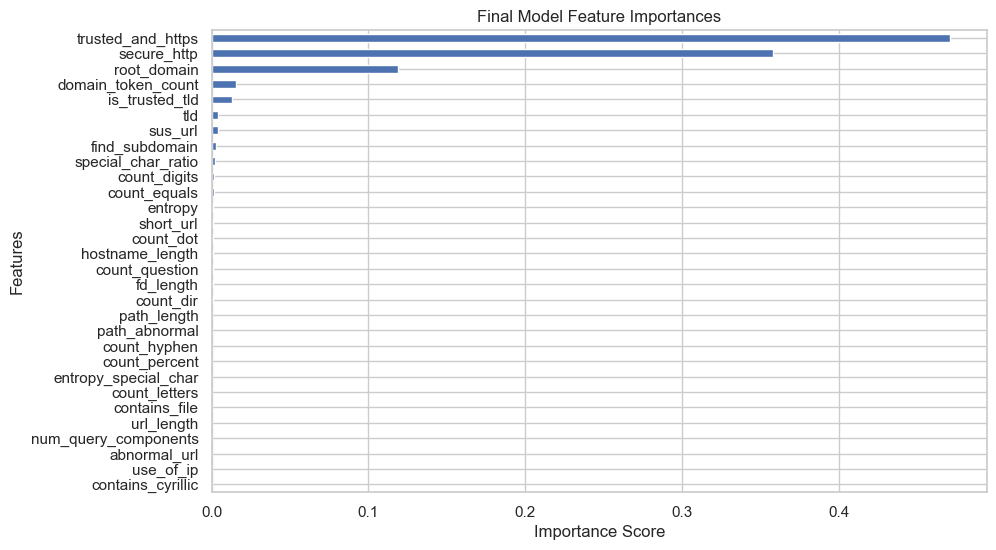


Evaluating the final model...
              precision    recall  f1-score   support

      benign       1.00      1.00      1.00    316449
   malicious       1.00      1.00      1.00    316561

    accuracy                           1.00    633010
   macro avg       1.00      1.00      1.00    633010
weighted avg       1.00      1.00      1.00    633010



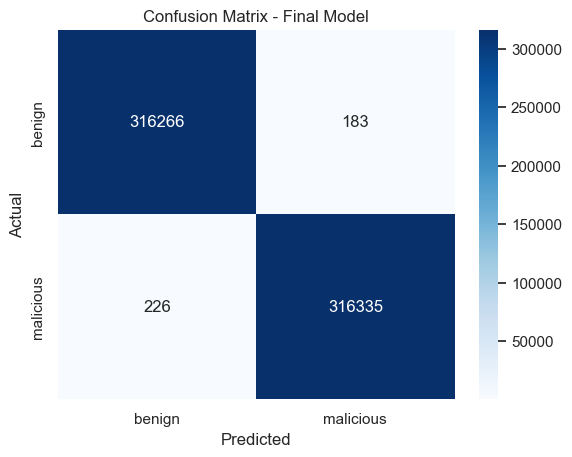

In [46]:
from sklearn.model_selection import GridSearchCV
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from xgboost import XGBClassifier
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn import metrics
from joblib import dump

# Define parameter grid for GridSearchCV with reduced combinations
param_grid = {
    'n_estimators': [100, 150],  # Reduce number of estimators to limit fits
    'max_depth': [4, 6],         # Lower max_depth options for simplicity
    'learning_rate': [0.01, 0.1],
    'gamma': [0.1, 0.2],         # Fewer gamma values to explore
    'subsample': [0.8],          # Fix subsample to one value
    'colsample_bytree': [0.8],   # Fix colsample_bytree to one value
    'min_child_weight': [1, 2]   # Reduce min_child_weight options
}

# Initialize base XGBoost model
base_xgb = XGBClassifier(
    random_state=42,
    n_jobs=-1
)

# Perform grid search for hyperparameter tuning
grid_search = GridSearchCV(
    estimator=base_xgb,
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=2
)

print("\nPerforming GridSearchCV...")
grid_search.fit(X_encoded, y_encoded)

# Output best parameters and score
print("\nBest parameters found:")
print(grid_search.best_params_)
print(f"\nBest cross-validation score: {grid_search.best_score_:.3f}")

# Train the final model using the best parameters
final_xgb = grid_search.best_estimator_
final_xgb.fit(X_encoded, y_encoded)

# Save the final model to disk using dump
dump(final_xgb, 'final_xgb_model.pkl')
print("Final model saved as 'final_xgb_model.pkl'")

# Feature Importances for Final Model
plt.figure(figsize=(10, 6))
feat_importances_final = pd.Series(final_xgb.feature_importances_, index=X_encoded.columns)
feat_importances_final.sort_values().plot(kind="barh", figsize=(10, 6))
plt.title('Final Model Feature Importances')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.show()

# Evaluate the final model
print("\nEvaluating the final model...")
y_pred = final_xgb.predict(X_encoded)
print(metrics.classification_report(y_encoded, y_pred, target_names=label_encoder.classes_))
cm = metrics.confusion_matrix(y_encoded, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.title("Confusion Matrix - Final Model")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


# ======================================
# 15. Predicting on Test URLs
# ======================================

Prepare a set of test URLs, apply feature engineering, and use the trained model to predict their classifications.

In [48]:
from IPython.display import display
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import KFold
from xgboost import XGBClassifier, plot_importance
from sklearn import metrics
from category_encoders import TargetEncoder
from sklearn.preprocessing import LabelEncoder

# Prepare test URLs
test_urls = [
    'https://www.google.com/info',
    'https://www.facebook.com',
    'https://www.amazon.com',
    'https://www.netflix.com',
    'https://www.reddit.com',
    'https://www.youtube.com/',
    'https://www.twitter.com',
    'https://www.linkedin.com',
    'https://www.instagram.com',
    'https://www.microsoft.com',
    'https://www.apple.com',
    'https://www.github.com',
    'https://www.wikipedia.org',
    'https://www.quora.com',
    'https://www.pinterest.com',
    'https://www.ebay.com',
    'https://www.dropbox.com',
    'https://www.paypal.com',
    'https://www.salesforce.com',
    'https://www.tesla.com',
    "allmusic.com/album/crazy-from-the-heat-r16990",
    "http://peluqueriadeautor.com/index.php?option=com_virtuemart&page=shop.browse&category_id=31&Itemid=70",
    "http://9779.info/%E5%84%BF%E7%AB%A5%E7%AB%8B%E4%BD",
    "http://9779.info/%E5%84%BF%E7%AB%A5%E7%AB%8B%E4%BD",
    "http://alexpay2.beget.tech",
    'http://www.pn-wuppertal.de/links/2-linkseite/5-httpwwwkrebshilfede',
    "https://spada.upnyk.ac.id/login/index.php",
    "https://bima.upnyk.ac.id/",
    "https://bankindonesia.co.id/",  # Indonesian bank with cyrillic characters
    "https://xn--80aa0cboq.xn--p1ai",  # Cyrillic domain with Russian TLD
    "https://bаnkindonesia.co.id/",
]

# Convert URLs to DataFrame
test_data = pd.DataFrame({'url': test_urls})

# Apply feature engineering functions
test_data['secure_http'] = test_data['url'].apply(secure_http)
test_data['url_length'] = test_data['url'].apply(url_length)
test_data['find_subdomain'] = test_data['url'].apply(find_subdomain)
test_data['tld'] = test_data['url'].apply(get_tld_func)
test_data['domain_token_count'] = test_data['url'].apply(domain_token_count)
test_data['hostname_length'] = test_data['url'].apply(hostname_length)
test_data['root_domain'] = test_data['url'].apply(extract_root_domain)
test_data['count_dot'] = test_data['url'].apply(count_dot)
test_data['count_dir'] = test_data['url'].apply(no_of_dir)
test_data['count_percent'] = test_data['url'].apply(
    lambda x: x.count('%') if isinstance(x, str) else 0)
test_data['count_question'] = test_data['url'].apply(
    lambda x: x.count('?') if isinstance(x, str) else 0)
test_data['count_hyphen'] = test_data['url'].apply(
    lambda x: x.count('-') if isinstance(x, str) else 0)
test_data['count_equals'] = test_data['url'].apply(
    lambda x: x.count('=') if isinstance(x, str) else 0)
test_data['count_digits'] = test_data['url'].apply(digit_count)
test_data['count_letters'] = test_data['url'].apply(letter_count)
test_data['fd_length'] = test_data['url'].apply(fd_length)
test_data['path_length'] = test_data['url'].apply(path_length)
test_data['num_query_components'] = test_data['url'].apply(num_query_components)
test_data['short_url'] = test_data['url'].apply(shortening_service)
test_data['abnormal_url'] = test_data['url'].apply(abnormal_url)
test_data['sus_url'] = test_data['url'].apply(suspicious_words)
test_data['use_of_ip'] = test_data['url'].apply(having_ip_address)
test_data['contains_file'] = test_data['url'].apply(contains_file)
test_data['path_abnormal'] = test_data['url'].apply(path_abnormal)
test_data['entropy'] = test_data['url'].apply(calculate_entropy)
test_data['special_char_ratio'] = test_data['url'].apply(special_char_ratio)

# Apply is_trusted_tld with parameter weight and https_bonus
test_data['is_trusted_tld'] = test_data['url'].apply(
    lambda url: is_trusted_tld(url, weight=10, https_bonus=5))

# Add the new feature for Cyrillic checking
test_data['contains_cyrillic'] = test_data['url'].apply(contains_cyrillic)

# Add combination features
test_data['trusted_and_https'] = test_data['is_trusted_tld'] * test_data['secure_http']
test_data['entropy_special_char'] = test_data['entropy'] * test_data['special_char_ratio']

# Select feature columns
feature_columns = [
    'secure_http', 'url_length', 'find_subdomain', 'tld', 'domain_token_count',
    'hostname_length', 'root_domain', 'count_dot', 'count_dir', 'count_percent', 'count_question',
    'count_hyphen', 'count_equals', 'count_digits', 'count_letters', 'fd_length',
    'path_length', 'num_query_components', 'short_url', 'abnormal_url',
    'sus_url', 'use_of_ip', 'contains_file', 'path_abnormal', 'is_trusted_tld',
    'trusted_and_https', 'contains_cyrillic', 'entropy', 'special_char_ratio', 'entropy_special_char'
]

# Select features
test_features = test_data[feature_columns]

# Handle missing categorical features for encoding
test_features[['find_subdomain', 'tld', 'root_domain']] = test_features[[
    'find_subdomain', 'tld', 'root_domain']].fillna('missing')

# Load TargetEncoder and XGBoost model
try:
    encoder_loaded = joblib.load('encoder.joblib')
    label_encoder_loaded = joblib.load('label_encoder.joblib')
    final_xgb_loaded = joblib.load('model_xgb.joblib')
    print("Encoders and model loaded successfully.")
except FileNotFoundError as e:
    print(f"Error: {e}. Ensure the encoder and model files exist.")
    exit(1)
except Exception as e:
    print(f"An error occurred while loading encoders and model: {e}")
    exit(1)

# Transform test_data using loaded encoder
X_test_encoded = encoder_loaded.transform(test_features)

print("\nFeature engineering on test data completed. Here's a preview:")
print(X_test_encoded.head())

# Predict using the loaded model
test_predictions_encoded = final_xgb_loaded.predict(X_test_encoded)

# Decode predictions to original labels
test_predictions = label_encoder_loaded.inverse_transform(test_predictions_encoded)

# Display predictions
test_data['Predicted_Type'] = test_predictions
print("\nTest URL Predictions:")
display(test_data[['url', 'Predicted_Type']])


Error: [Errno 2] No such file or directory: 'encoder.joblib'. Ensure the encoder and model files exist.

Feature engineering on test data completed. Here's a preview:
   secure_http  url_length  find_subdomain       tld  domain_token_count  \
0            1    2.995732        0.497203  0.356651            1.386294   
1            1    2.833213        0.497203  0.356651            1.386294   
2            1    2.708050        0.497203  0.356651            1.386294   
3            1    2.772589        0.497203  0.356651            1.386294   
4            1    2.708050        0.497203  0.356651            1.386294   

   hostname_length  root_domain  count_dot  count_dir  count_percent  ...  \
0               14     0.772267          2          1              0  ...   
1               16     0.005887          2          0              0  ...   
2               14     0.008738          2          0              0  ...   
3               15     0.000002          2          0              0

/var/folders/2t/4pk9n9cn4vq4vq2kybwvrbqc0000gn/T/ipykernel_46737/3837224678.py:108: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  test_features[['find_subdomain', 'tld', 'root_domain']] = test_features[[


,url,Predicted_Type
0,https://www.google.com/info,benign
1,https://www.facebook.com,benign
2,https://www.amazon.com,benign
3,https://www.netflix.com,benign
4,https://www.reddit.com,benign
5,https://www.youtube.com/,benign
6,https://www.twitter.com,benign
7,https://www.linkedin.com,benign
8,https://www.instagram.com,malicious
9,https://www.microsoft.com,benign
